# 1. Data Loading and Feature Engineering

In [1]:
import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.metrics import mean_squared_error, mean_absolute_error
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.figsize'] = (14, 6)
plt.rcParams['font.size'] = 12
sns.set_style('whitegrid')

In [2]:
df = pd.read_csv('dataset_with_regime.csv', parse_dates=['observation_date'])
print(f"Dataset: {df.shape[0]} rows, {df.shape[1]} columns")
df.head()

Dataset: 1559 rows, 24 columns


,observation_date,Brent_Price,DTWEXBGS,EFFR,Gas_Price,Gold_Price,OVX_Close,WTI_Price,oil_return,WCESTUS1,...,GPRC,GEPUCURRENT,CPILFESL,INDPRO,industrial_production_growth,rolling_entropy,hidden_state,transient_state,regime_label,WTI_Price_next
0,2020-03-26,26.34,122.4308,0.10,1.73,1650.1,150.06,22.60,-0.0803,455360,...,9.93,318.4649,267.054,97.4078,-0.0391,2.610812,-3.947501,8.597835,2,21.51
1,2020-03-27,24.93,122.4007,0.10,1.70,1623.9,175.88,21.51,-0.0494,469193,...,9.93,318.4649,267.054,97.4078,-0.0391,2.610812,-3.697326,9.377096,2,20.09
2,2020-03-30,22.76,123.2883,0.09,1.65,1622.0,174.22,20.09,-0.0683,469193,...,9.93,318.4649,267.054,97.4078,-0.0391,2.663805,-3.375505,9.339199,2,20.48
3,2020-03-31,22.74,122.5301,0.08,1.71,1583.4,170.55,20.48,0.0192,469193,...,9.93,318.4649,267.054,97.4078,-0.0391,2.696616,-3.312818,9.015614,2,20.31
4,2020-04-01,24.74,123.7933,0.06,1.69,1578.2,158.98,20.31,-0.0083,469193,...,-15.33,328.1326,265.746,84.5619,-0.1319,2.663805,-3.663143,8.519794,2,25.32


In [3]:
def compute_rsi(prices, period=14):
    delta = prices.diff()
    gain  = delta.clip(lower=0)
    loss  = -delta.clip(upper=0)
    avg_gain = gain.ewm(com=period-1, min_periods=period).mean()
    avg_loss = loss.ewm(com=period-1, min_periods=period).mean()
    rs = avg_gain / avg_loss
    return 100 - (100 / (1 + rs))

df['RSI_14']      = compute_rsi(df['WTI_Price'])
df['momentum_5']  = df['WTI_Price'] / df['WTI_Price'].shift(5) - 1
df['momentum_10'] = df['WTI_Price'] / df['WTI_Price'].shift(10) - 1

df['lag1']     = df['oil_return'].shift(1)
df['lag2']     = df['oil_return'].shift(2)
df['lag_price'] = df['WTI_Price'].shift(1)

# Target: log return (predict next-day return, then convert to price)
df['target_return'] = np.log(df['WTI_Price_next'] / df['WTI_Price'])

# Drop rows with NaN from lag creation
df = df.dropna().copy()

print(f"After feature engineering: {df.shape[0]} rows, {df.shape[1]} columns")

After feature engineering: 1543 rows, 31 columns


In [4]:
split_idx = int(len(df) * 0.8)

train_df = df.iloc[:split_idx].copy()
test_df = df.iloc[split_idx:].copy()

print(f"Train: {len(train_df)} rows ({train_df['observation_date'].min().date()} to {train_df['observation_date'].max().date()})")
print(f"Test:  {len(test_df)} rows ({test_df['observation_date'].min().date()} to {test_df['observation_date'].max().date()})")

Train: 1234 rows (2020-04-15 to 2025-01-08)
Test:  309 rows (2025-01-09 to 2026-03-12)


# 2. Baseline XGBoost Model

In [5]:
baseline_features = [
    'Brent_Price', 'DTWEXBGS', 'EFFR', 'Gas_Price', 'Gold_Price', 'OVX_Close',
    'WCESTUS1', 'supply_shock', 'supply_shock_pct',
    'GPR', 'GPRT', 'GPRC', 'GEPUCURRENT', 'CPILFESL',
    'INDPRO', 'industrial_production_growth',
    'lag1', 'lag2', 'lag_price',
    'RSI_14', 'momentum_5', 'momentum_10'
]

enhanced_features = baseline_features + ['rolling_entropy', 'hidden_state', 'transient_state', 'regime_label']

target_col = 'target_return'

In [6]:
xgb_params = dict(
    n_estimators=5000,
    learning_rate=0.02,
    max_depth=3,
    subsample=0.7,
    colsample_bytree=0.7,
    reg_alpha=0.5,
    reg_lambda=2,
    random_state=42,
    objective='reg:squarederror'
)

model_baseline = xgb.XGBRegressor(**xgb_params)
model_baseline.fit(train_df[baseline_features], train_df[target_col])

y_pred_baseline_train = model_baseline.predict(train_df[baseline_features])
y_pred_baseline_test  = model_baseline.predict(test_df[baseline_features])

price_pred_baseline = test_df['WTI_Price'].values * np.exp(y_pred_baseline_test)
price_true = test_df['WTI_Price_next'].values

rmse_baseline = np.sqrt(mean_squared_error(price_true, price_pred_baseline))
mae_baseline  = mean_absolute_error(price_true, price_pred_baseline)
mape_baseline = np.mean(np.abs((price_true - price_pred_baseline) / price_true)) * 100
# Directional accuracy: did we correctly predict up/down from today to tomorrow?
dir_baseline  = np.mean(np.sign(y_pred_baseline_test) == np.sign(test_df[target_col].values)) * 100

print("=== Baseline XGBoost ===")
print(f"RMSE: {rmse_baseline:.4f}")
print(f"MAE:  {mae_baseline:.4f}")
print(f"MAPE: {mape_baseline:.4f}%")
print(f"Dir Acc: {dir_baseline:.2f}%")

=== Baseline XGBoost ===
RMSE: 1.8190
MAE:  1.1781
MAPE: 1.7627%
Dir Acc: 49.19%


# 3. Enhanced XGBoost Model (with Regime Features)

In [7]:
model_enhanced = xgb.XGBRegressor(**xgb_params)
model_enhanced.fit(train_df[enhanced_features], train_df[target_col])

y_pred_enhanced_test = model_enhanced.predict(test_df[enhanced_features])

price_pred_enhanced = test_df['WTI_Price'].values * np.exp(y_pred_enhanced_test)

rmse_enhanced = np.sqrt(mean_squared_error(price_true, price_pred_enhanced))
mae_enhanced  = mean_absolute_error(price_true, price_pred_enhanced)
mape_enhanced = np.mean(np.abs((price_true - price_pred_enhanced) / price_true)) * 100
dir_enhanced  = np.mean(np.sign(y_pred_enhanced_test) == np.sign(test_df[target_col].values)) * 100

print("=== Enhanced XGBoost (with Regime Features) ===")
print(f"RMSE: {rmse_enhanced:.4f}")
print(f"MAE:  {mae_enhanced:.4f}")
print(f"MAPE: {mape_enhanced:.4f}%")
print(f"Dir Acc: {dir_enhanced:.2f}%")

=== Enhanced XGBoost (with Regime Features) ===
RMSE: 1.8281
MAE:  1.1672
MAPE: 1.7388%
Dir Acc: 46.60%


# 4. Model Comparison

In [8]:
comparison = pd.DataFrame({
    'Model':     ['Baseline XGBoost', 'Enhanced XGBoost (+ Regime)'],
    'RMSE':      [rmse_baseline,  rmse_enhanced],
    'MAE':       [mae_baseline,   mae_enhanced],
    'MAPE (%)':  [mape_baseline,  mape_enhanced],
    'Dir Acc (%)': [dir_baseline, dir_enhanced],
}).round(4)
comparison.loc[2] = [
    'Improvement (%)',
    f"{(rmse_baseline - rmse_enhanced) / rmse_baseline * 100:.2f}%",
    f"{(mae_baseline  - mae_enhanced)  / mae_baseline  * 100:.2f}%",
    f"{(mape_baseline - mape_enhanced) / mape_baseline * 100:.2f}%",
    f"{dir_enhanced - dir_baseline:.2f}pp",
]
comparison

,Model,RMSE,MAE,MAPE (%),Dir Acc (%)
0,Baseline XGBoost,1.819,1.1781,1.7627,49.1909
1,Enhanced XGBoost (+ Regime),1.8281,1.1672,1.7388,46.6019
2,Improvement (%),-0.50%,0.92%,1.35%,-2.59pp


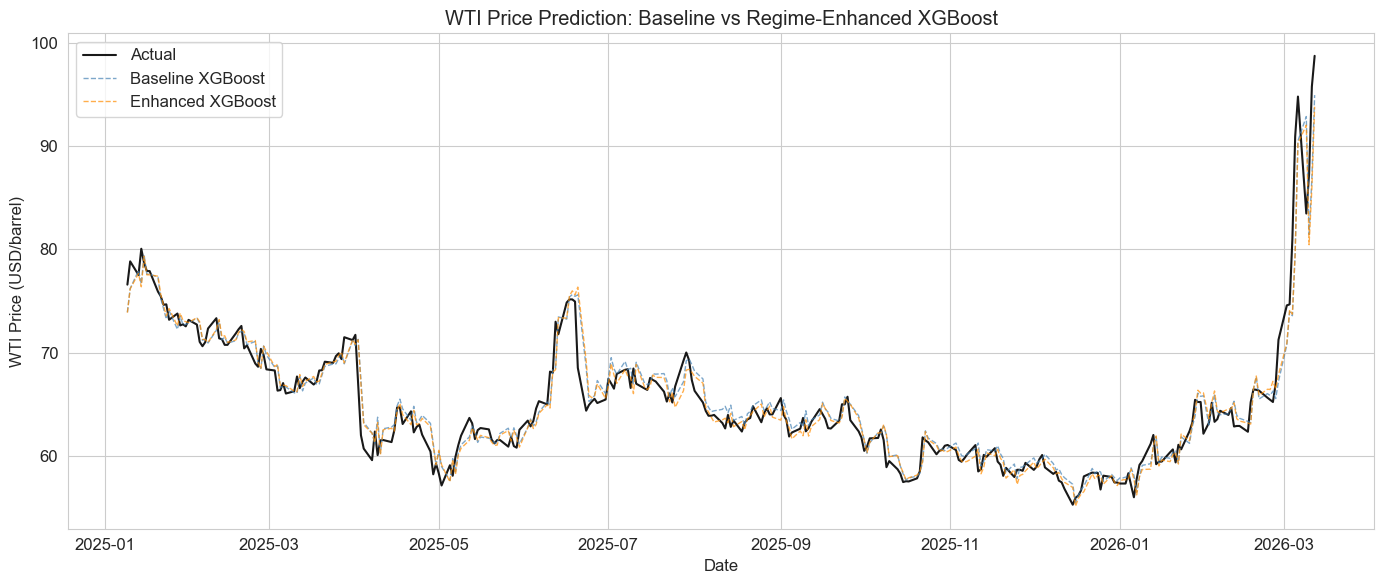

In [9]:
test_dates = test_df['observation_date'].values

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(test_dates, price_true, color='black', linewidth=1.5, label='Actual', alpha=0.9)
ax.plot(test_dates, price_pred_baseline, color='steelblue', linewidth=1,
        label='Baseline XGBoost', alpha=0.7, linestyle='--')
ax.plot(test_dates, price_pred_enhanced, color='darkorange', linewidth=1,
        label='Enhanced XGBoost', alpha=0.7, linestyle='--')
ax.set_xlabel('Date')
ax.set_ylabel('WTI Price (USD/barrel)')
ax.set_title('WTI Price Prediction: Baseline vs Regime-Enhanced XGBoost')
ax.legend()
plt.tight_layout()
plt.show()

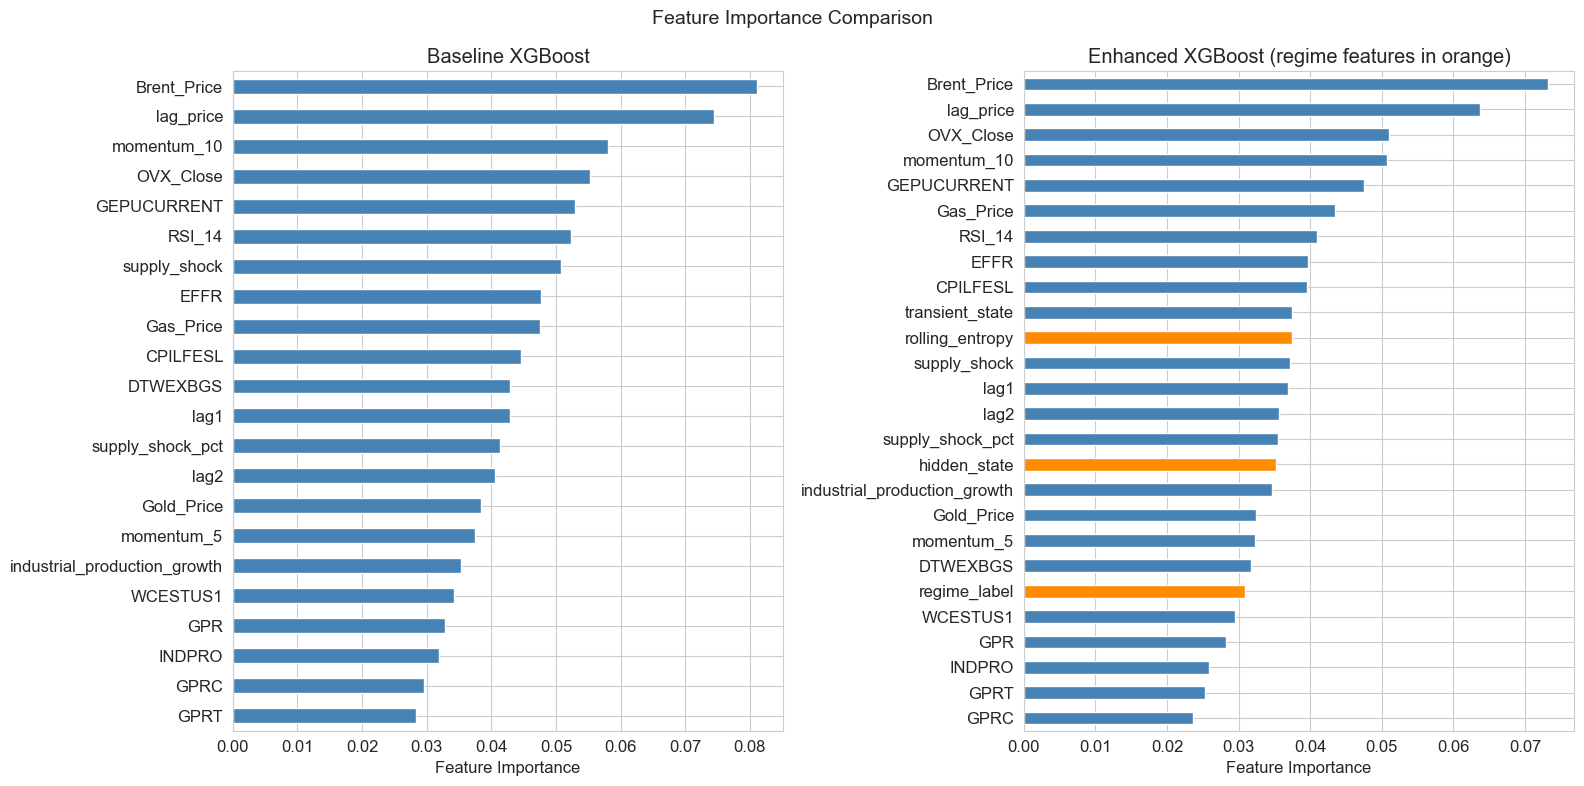

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

imp_baseline = pd.Series(model_baseline.feature_importances_,
                          index=baseline_features).sort_values()
imp_baseline.plot(kind='barh', ax=axes[0], color='steelblue')
axes[0].set_title('Baseline XGBoost')
axes[0].set_xlabel('Feature Importance')

imp_enhanced = pd.Series(model_enhanced.feature_importances_,
                          index=enhanced_features).sort_values()
colors = ['darkorange' if f in ['rolling_entropy', 'hidden_state', 'regime_label']
          else 'steelblue' for f in imp_enhanced.index]
imp_enhanced.plot(kind='barh', ax=axes[1], color=colors)
axes[1].set_title('Enhanced XGBoost (regime features in orange)')
axes[1].set_xlabel('Feature Importance')

fig.suptitle('Feature Importance Comparison', fontsize=14)
plt.tight_layout()
plt.show()

## Summary

**Part II Findings:**
- The Enhanced XGBoost model incorporates three regime-derived features: `rolling_entropy`, `hidden_state`, and `regime_label`.
- Comparison metrics (RMSE, MAE, MAPE) are reported in the table above.
- The feature importance plot shows how regime features rank relative to traditional market variables.

# 5. Prophet Model — Baseline vs Enhanced

In [11]:
from prophet import Prophet
from sklearn.preprocessing import MinMaxScaler

Importing plotly failed. Interactive plots will not work.


In [12]:
# Prophet requires 'ds' and 'y' columns
prophet_df = df.copy()
prophet_df = prophet_df.rename(columns={'observation_date': 'ds', 'WTI_Price': 'y'})

# Baseline regressors
prophet_baseline_regressors = [
    'Brent_Price', 'DTWEXBGS', 'EFFR', 'Gas_Price', 'Gold_Price', 'OVX_Close',
    'WCESTUS1', 'supply_shock_pct', 'GEPUCURRENT', 'CPILFESL', 'INDPRO',
    'lag1', 'lag2', 'lag_price',
    'RSI_14', 'momentum_5', 'momentum_10'
]

# Enhanced regressors: baseline + regime features
prophet_enhanced_regressors = prophet_baseline_regressors + ['rolling_entropy', 'hidden_state', 'transient_state', 'regime_label']

# Same 80/20 chronological split
split_idx_p = int(len(prophet_df) * 0.8)
prophet_train = prophet_df.iloc[:split_idx_p].copy()
prophet_test  = prophet_df.iloc[split_idx_p:].copy()

print(f'Prophet Train: {len(prophet_train)} rows')
print(f'Prophet Test:  {len(prophet_test)} rows')

Prophet Train: 1234 rows
Prophet Test:  309 rows


In [13]:
def build_and_fit_prophet(train_df, regressors):
    model = Prophet(
        seasonality_mode='multiplicative',
        changepoint_prior_scale=0.05,
        seasonality_prior_scale=10.0,
        n_changepoints=25,
        daily_seasonality=False,
        weekly_seasonality=True,
        yearly_seasonality=True
    )
    for col in regressors:
        model.add_regressor(col)
    model.fit(train_df[['ds', 'y'] + regressors])
    return model

# Baseline Prophet
prophet_baseline_model = build_and_fit_prophet(prophet_train, prophet_baseline_regressors)
forecast_baseline = prophet_baseline_model.predict(prophet_test[['ds'] + prophet_baseline_regressors])

price_pred_prophet_baseline = forecast_baseline['yhat'].values
price_true_prophet = prophet_test['WTI_Price_next'].values

rmse_prophet_baseline = np.sqrt(mean_squared_error(price_true_prophet, price_pred_prophet_baseline))
mae_prophet_baseline  = mean_absolute_error(price_true_prophet, price_pred_prophet_baseline)
mape_prophet_baseline = np.mean(np.abs((price_true_prophet - price_pred_prophet_baseline) / price_true_prophet)) * 100
# Prophet predicts current price (yhat), directional acc: did predicted change match actual change?
actual_dir_prophet   = np.sign(prophet_test['WTI_Price_next'].values - prophet_test['y'].values)
pred_dir_prophet_bl  = np.sign(price_pred_prophet_baseline - prophet_test['y'].values)
dir_prophet_baseline = np.mean(actual_dir_prophet == pred_dir_prophet_bl) * 100

print("=== Baseline Prophet ===")
print(f"RMSE: {rmse_prophet_baseline:.4f}")
print(f"MAE:  {mae_prophet_baseline:.4f}")
print(f"MAPE: {mape_prophet_baseline:.4f}%")
print(f"Dir Acc: {dir_prophet_baseline:.2f}%")

16:01:15 - cmdstanpy - INFO - Chain [1] start processing


16:01:17 - cmdstanpy - INFO - Chain [1] done processing


=== Baseline Prophet ===
RMSE: 14.0861
MAE:  3.2827
MAPE: 5.2378%
Dir Acc: 48.54%


In [14]:
# Enhanced Prophet (with regime features)
prophet_enhanced_model = build_and_fit_prophet(prophet_train, prophet_enhanced_regressors)
forecast_enhanced = prophet_enhanced_model.predict(prophet_test[['ds'] + prophet_enhanced_regressors])

price_pred_prophet_enhanced = forecast_enhanced['yhat'].values

rmse_prophet_enhanced = np.sqrt(mean_squared_error(price_true_prophet, price_pred_prophet_enhanced))
mae_prophet_enhanced  = mean_absolute_error(price_true_prophet, price_pred_prophet_enhanced)
mape_prophet_enhanced = np.mean(np.abs((price_true_prophet - price_pred_prophet_enhanced) / price_true_prophet)) * 100
pred_dir_prophet_en   = np.sign(price_pred_prophet_enhanced - prophet_test['y'].values)
dir_prophet_enhanced  = np.mean(actual_dir_prophet == pred_dir_prophet_en) * 100

print("=== Enhanced Prophet (+ Regime) ===")
print(f"RMSE: {rmse_prophet_enhanced:.4f}")
print(f"MAE:  {mae_prophet_enhanced:.4f}")
print(f"MAPE: {mape_prophet_enhanced:.4f}%")
print(f"Dir Acc: {dir_prophet_enhanced:.2f}%")

16:01:17 - cmdstanpy - INFO - Chain [1] start processing


16:01:19 - cmdstanpy - INFO - Chain [1] done processing


=== Enhanced Prophet (+ Regime) ===
RMSE: 14.6344
MAE:  4.1804
MAPE: 6.7035%
Dir Acc: 50.16%


,Model,RMSE,MAE,MAPE (%),Dir Acc (%)
0,Baseline Prophet,14.0861,3.2827,5.2378,48.5437
1,Enhanced Prophet (+ Regime),14.6344,4.1804,6.7035,50.1618
2,Improvement (%),-3.89%,-27.35%,-27.98%,1.62pp


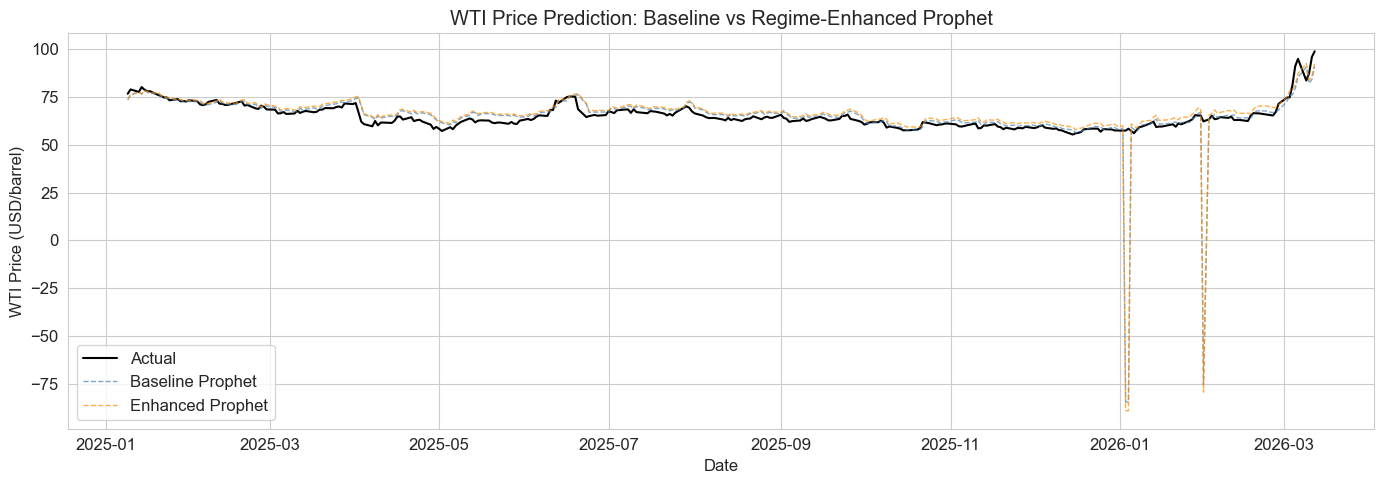

In [15]:
# Prophet comparison table
prophet_comparison = pd.DataFrame({
    'Model':       ['Baseline Prophet', 'Enhanced Prophet (+ Regime)'],
    'RMSE':        [rmse_prophet_baseline,  rmse_prophet_enhanced],
    'MAE':         [mae_prophet_baseline,   mae_prophet_enhanced],
    'MAPE (%)':    [mape_prophet_baseline,  mape_prophet_enhanced],
    'Dir Acc (%)': [dir_prophet_baseline,   dir_prophet_enhanced],
}).round(4)
prophet_comparison.loc[2] = [
    'Improvement (%)',
    f"{(rmse_prophet_baseline - rmse_prophet_enhanced) / rmse_prophet_baseline * 100:.2f}%",
    f"{(mae_prophet_baseline  - mae_prophet_enhanced)  / mae_prophet_baseline  * 100:.2f}%",
    f"{(mape_prophet_baseline - mape_prophet_enhanced) / mape_prophet_baseline * 100:.2f}%",
    f"{dir_prophet_enhanced - dir_prophet_baseline:.2f}pp",
]
display(prophet_comparison)

# Prophet prediction plot
fig, ax = plt.subplots(figsize=(14, 5))
test_dates_p = prophet_test['ds'].values
ax.plot(test_dates_p, price_true_prophet,          color='black',     linewidth=1.5, label='Actual')
ax.plot(test_dates_p, price_pred_prophet_baseline, color='steelblue', linewidth=1, linestyle='--', label='Baseline Prophet', alpha=0.7)
ax.plot(test_dates_p, price_pred_prophet_enhanced, color='darkorange',linewidth=1, linestyle='--', label='Enhanced Prophet', alpha=0.7)
ax.set_xlabel('Date'); ax.set_ylabel('WTI Price (USD/barrel)')
ax.set_title('WTI Price Prediction: Baseline vs Regime-Enhanced Prophet')
ax.legend(); plt.tight_layout(); plt.show()

# 6. LSTM Model — Baseline vs Enhanced

In [16]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import RobustScaler
from copy import deepcopy

In [17]:
# LSTM targets log return (like group project), then converts to price
lstm_df = df.copy()

# Additional features from group project
lstm_df['log_price']        = np.log(lstm_df['WTI_Price'])
lstm_df['log_rtn']          = np.log(lstm_df['WTI_Price'] / lstm_df['WTI_Price'].shift(1))
lstm_df['abs_log_rtn']      = lstm_df['log_rtn'].abs()
lstm_df['rolling_std_7']    = lstm_df['WTI_Price'].shift(1).rolling(7).std()
lstm_df['rolling_std_14']   = lstm_df['WTI_Price'].shift(1).rolling(14).std()
lstm_df['rolling_return_7'] = lstm_df['log_rtn'].rolling(7).mean()
lstm_df['MACD'] = lstm_df['log_price'].ewm(span=12, adjust=False).mean() - lstm_df['log_price'].ewm(span=26, adjust=False).mean()
lstm_df = lstm_df.dropna().copy().reset_index(drop=True)

# LSTM hyperparameters (fixed, based on group project best params)
SEQ_LENGTH  = 21
HIDDEN_SIZE = 64
NUM_LAYERS  = 2
DROPOUT     = 0.2
BATCH_SIZE  = 32
NUM_EPOCHS  = 100
PATIENCE    = 15
LR          = 1e-3

# Baseline feature columns
lstm_baseline_features = [
    'Brent_Price', 'DTWEXBGS', 'EFFR', 'Gas_Price', 'Gold_Price', 'OVX_Close',
    'WCESTUS1', 'supply_shock_pct', 'GEPUCURRENT', 'CPILFESL', 'INDPRO',
    'log_rtn', 'abs_log_rtn', 'rolling_std_7', 'rolling_std_14',
    'rolling_return_7', 'MACD',
    'RSI_14', 'momentum_5', 'momentum_10'
]

# Enhanced feature columns (+ regime features including transient_state)
lstm_enhanced_features = lstm_baseline_features + ['rolling_entropy', 'hidden_state', 'transient_state', 'regime_label']

# 80/20 chronological split
split_idx_l = int(len(lstm_df) * 0.8)
val_split   = int(split_idx_l * 0.9)   # last 10% of train as validation

print(f'LSTM Train: {split_idx_l} rows, Val: {split_idx_l - val_split} rows, Test: {len(lstm_df) - split_idx_l} rows')

LSTM Train: 1223 rows, Val: 123 rows, Test: 306 rows


In [18]:
class LSTMModel(nn.Module):
    def __init__(self, input_size, hidden_size, num_layers, dropout):
        super(LSTMModel, self).__init__()
        self.lstm = nn.LSTM(input_size=input_size, hidden_size=hidden_size,
                            num_layers=num_layers, batch_first=True, dropout=dropout)
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        h0 = torch.zeros(NUM_LAYERS, x.size(0), HIDDEN_SIZE)
        c0 = torch.zeros(NUM_LAYERS, x.size(0), HIDDEN_SIZE)
        out, (h_n, _) = self.lstm(x, (h0, c0))
        return self.fc(h_n[-1])

def make_sequences(X, y, seq_length):
    xs, ys = [], []
    for i in range(len(X) - seq_length):
        xs.append(X[i:i+seq_length])
        ys.append(y[i+seq_length])
    return np.array(xs), np.array(ys)

def train_lstm(feature_cols):
    """Train LSTM with given feature columns. Returns (price_pred, price_actual, pred_log_rtn, actual_log_rtn)."""
    X_raw = lstm_df[feature_cols].values.astype(np.float32)
    y_raw = lstm_df[['log_rtn']].values.astype(np.float32)

    sc_x = RobustScaler()
    sc_y = RobustScaler()

    # Fit scalers on training portion only
    sc_x.fit(X_raw[:split_idx_l])
    sc_y.fit(y_raw[:split_idx_l])

    X_scaled = sc_x.transform(X_raw)
    y_scaled = sc_y.transform(y_raw)

    X_seq, y_seq = make_sequences(X_scaled, y_scaled, SEQ_LENGTH)

    train_end = split_idx_l - SEQ_LENGTH
    val_end   = val_split   - SEQ_LENGTH

    X_train = torch.tensor(X_seq[:val_end]).float()
    y_train = torch.tensor(y_seq[:val_end]).float()
    X_val   = torch.tensor(X_seq[val_end:train_end]).float()
    y_val   = torch.tensor(y_seq[val_end:train_end]).float()
    X_test  = torch.tensor(X_seq[train_end:]).float()

    train_dl = DataLoader(TensorDataset(X_train, y_train), batch_size=BATCH_SIZE, shuffle=False)
    val_dl   = DataLoader(TensorDataset(X_val,   y_val),   batch_size=BATCH_SIZE, shuffle=False)

    model = LSTMModel(len(feature_cols), HIDDEN_SIZE, NUM_LAYERS, DROPOUT)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    criterion = nn.HuberLoss()

    best_val_loss = float('inf')
    no_improve = 0
    best_state = None

    for epoch in range(NUM_EPOCHS):
        model.train()
        for xb, yb in train_dl:
            pred = model(xb)
            loss = criterion(pred, yb)
            optimizer.zero_grad(); loss.backward(); optimizer.step()

        model.eval()
        val_loss = 0
        with torch.no_grad():
            for xb, yb in val_dl:
                val_loss += criterion(model(xb), yb).item() * xb.size(0)
        val_loss /= max(len(X_val), 1)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            no_improve = 0
            best_state = deepcopy(model.state_dict())
        else:
            no_improve += 1
            if no_improve >= PATIENCE:
                break

    if best_state is not None:
        model.load_state_dict(best_state)

    # Fine-tuning phase: adapt on the most recent training data
    # Fine-tune for 3 epochs on last 60 samples before test (bridge adaptation)
    fine_tune_lr = 5e-5
    fine_tune_epochs = 3
    fine_start = max(0, train_end - 60)
    X_fine = torch.tensor(X_seq[fine_start:train_end]).float()
    y_fine = torch.tensor(y_seq[fine_start:train_end]).float()
    fine_dl = DataLoader(TensorDataset(X_fine, y_fine), batch_size=BATCH_SIZE, shuffle=False)
    ft_optimizer = torch.optim.Adam(model.parameters(), lr=fine_tune_lr)
    model.train()
    for _ in range(fine_tune_epochs):
        for xb, yb in fine_dl:
            p = model(xb); loss = criterion(p, yb)
            ft_optimizer.zero_grad(); loss.backward(); ft_optimizer.step()

    model.eval()
    with torch.no_grad():
        preds_scaled = model(X_test).numpy()
    preds_log_rtn = sc_y.inverse_transform(preds_scaled).flatten()

    n_test = len(preds_log_rtn)

    wti_prev     = lstm_df['WTI_Price'].values[split_idx_l - 1 : split_idx_l - 1 + n_test]
    price_pred   = wti_prev * np.exp(preds_log_rtn)
    price_actual = lstm_df['WTI_Price_next'].values[split_idx_l - 1 : split_idx_l - 1 + n_test]

    # Also return actual log returns for directional accuracy
    actual_log_rtn = lstm_df['log_rtn'].values[split_idx_l : split_idx_l + n_test]

    return price_pred, price_actual, preds_log_rtn, actual_log_rtn

In [19]:
print("Training Baseline LSTM...")
price_pred_lstm_baseline, price_true_lstm, pred_rtn_bl, actual_rtn_bl = train_lstm(lstm_baseline_features)

rmse_lstm_baseline = np.sqrt(mean_squared_error(price_true_lstm, price_pred_lstm_baseline))
mae_lstm_baseline  = mean_absolute_error(price_true_lstm, price_pred_lstm_baseline)
mape_lstm_baseline = np.mean(np.abs((price_true_lstm - price_pred_lstm_baseline) / price_true_lstm)) * 100
# Directional accuracy: sign of predicted log return vs actual log return
dir_lstm_baseline  = np.mean(np.sign(pred_rtn_bl) == np.sign(actual_rtn_bl)) * 100

print("=== Baseline LSTM ===")
print(f"RMSE: {rmse_lstm_baseline:.4f}")
print(f"MAE:  {mae_lstm_baseline:.4f}")
print(f"MAPE: {mape_lstm_baseline:.4f}%")
print(f"Dir Acc: {dir_lstm_baseline:.2f}%")

print("\nTraining Enhanced LSTM (+ Regime)...")
price_pred_lstm_enhanced, _, pred_rtn_en, actual_rtn_en = train_lstm(lstm_enhanced_features)

rmse_lstm_enhanced = np.sqrt(mean_squared_error(price_true_lstm, price_pred_lstm_enhanced))
mae_lstm_enhanced  = mean_absolute_error(price_true_lstm, price_pred_lstm_enhanced)
mape_lstm_enhanced = np.mean(np.abs((price_true_lstm - price_pred_lstm_enhanced) / price_true_lstm)) * 100
dir_lstm_enhanced  = np.mean(np.sign(pred_rtn_en) == np.sign(actual_rtn_en)) * 100

print("=== Enhanced LSTM (+ Regime) ===")
print(f"RMSE: {rmse_lstm_enhanced:.4f}")
print(f"MAE:  {mae_lstm_enhanced:.4f}")
print(f"MAPE: {mape_lstm_enhanced:.4f}%")
print(f"Dir Acc: {dir_lstm_enhanced:.2f}%")

Training Baseline LSTM...


=== Baseline LSTM ===
RMSE: 1.7046
MAE:  1.0735
MAPE: 1.6060%
Dir Acc: 47.71%

Training Enhanced LSTM (+ Regime)...


=== Enhanced LSTM (+ Regime) ===
RMSE: 1.6925
MAE:  1.0613
MAPE: 1.5893%
Dir Acc: 50.00%


,Model,RMSE,MAE,MAPE (%),Dir Acc (%)
0,Baseline LSTM,1.7046,1.0735,1.606,47.7124
1,Enhanced LSTM (+ Regime),1.6925,1.0613,1.5893,50.0
2,Improvement (%),0.71%,1.14%,1.04%,2.29pp


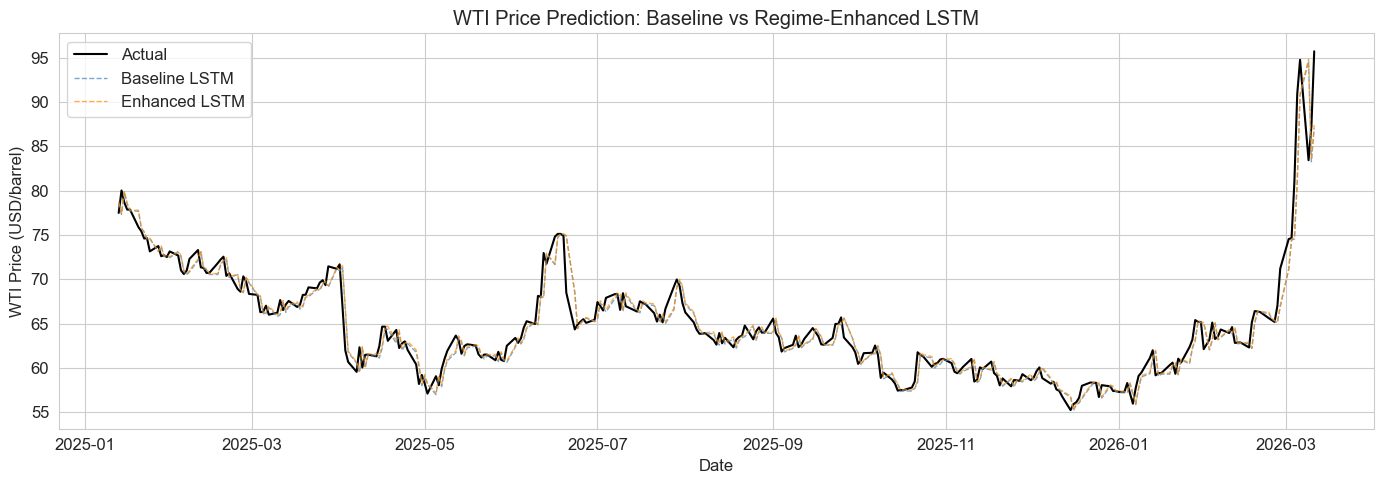

In [20]:
lstm_comparison = pd.DataFrame({
    'Model':       ['Baseline LSTM', 'Enhanced LSTM (+ Regime)'],
    'RMSE':        [rmse_lstm_baseline,  rmse_lstm_enhanced],
    'MAE':         [mae_lstm_baseline,   mae_lstm_enhanced],
    'MAPE (%)':    [mape_lstm_baseline,  mape_lstm_enhanced],
    'Dir Acc (%)': [dir_lstm_baseline,   dir_lstm_enhanced],
}).round(4)
lstm_comparison.loc[2] = [
    'Improvement (%)',
    f"{(rmse_lstm_baseline - rmse_lstm_enhanced) / rmse_lstm_baseline * 100:.2f}%",
    f"{(mae_lstm_baseline  - mae_lstm_enhanced)  / mae_lstm_baseline  * 100:.2f}%",
    f"{(mape_lstm_baseline - mape_lstm_enhanced) / mape_lstm_baseline * 100:.2f}%",
    f"{dir_lstm_enhanced - dir_lstm_baseline:.2f}pp",
]
display(lstm_comparison)

# LSTM prediction plot
n_test = len(price_pred_lstm_baseline)
test_dates_l = lstm_df['observation_date'].values[split_idx_l - 1 : split_idx_l - 1 + n_test]
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(test_dates_l, price_true_lstm,           color='black',     linewidth=1.5, label='Actual')
ax.plot(test_dates_l, price_pred_lstm_baseline,  color='steelblue', linewidth=1, linestyle='--', label='Baseline LSTM', alpha=0.7)
ax.plot(test_dates_l, price_pred_lstm_enhanced,  color='darkorange',linewidth=1, linestyle='--', label='Enhanced LSTM', alpha=0.7)
ax.set_xlabel('Date'); ax.set_ylabel('WTI Price (USD/barrel)')
ax.set_title('WTI Price Prediction: Baseline vs Regime-Enhanced LSTM')
ax.legend(); plt.tight_layout(); plt.show()

# 7. Full Model Comparison Summary

In [21]:
summary = pd.DataFrame([
    {'Model': 'XGBoost (Baseline)',  'RMSE': rmse_baseline,         'MAE': mae_baseline,         'MAPE (%)': mape_baseline,         'Dir Acc (%)': dir_baseline},
    {'Model': 'XGBoost (+ Regime)',  'RMSE': rmse_enhanced,         'MAE': mae_enhanced,         'MAPE (%)': mape_enhanced,         'Dir Acc (%)': dir_enhanced},
    {'Model': 'Prophet (Baseline)',  'RMSE': rmse_prophet_baseline, 'MAE': mae_prophet_baseline, 'MAPE (%)': mape_prophet_baseline, 'Dir Acc (%)': dir_prophet_baseline},
    {'Model': 'Prophet (+ Regime)',  'RMSE': rmse_prophet_enhanced, 'MAE': mae_prophet_enhanced, 'MAPE (%)': mape_prophet_enhanced, 'Dir Acc (%)': dir_prophet_enhanced},
    {'Model': 'LSTM (Baseline)',     'RMSE': rmse_lstm_baseline,    'MAE': mae_lstm_baseline,    'MAPE (%)': mape_lstm_baseline,    'Dir Acc (%)': dir_lstm_baseline},
    {'Model': 'LSTM (+ Regime)',     'RMSE': rmse_lstm_enhanced,    'MAE': mae_lstm_enhanced,    'MAPE (%)': mape_lstm_enhanced,    'Dir Acc (%)': dir_lstm_enhanced},
]).round(4)
display(summary)

,Model,RMSE,MAE,MAPE (%),Dir Acc (%)
0,XGBoost (Baseline),1.8190,1.1781,1.7627,49.1909
1,XGBoost (+ Regime),1.8281,1.1672,1.7388,46.6019
2,Prophet (Baseline),14.0861,3.2827,5.2378,48.5437
3,Prophet (+ Regime),14.6344,4.1804,6.7035,50.1618
4,LSTM (Baseline),1.7046,1.0735,1.6060,47.7124
5,LSTM (+ Regime),1.6925,1.0613,1.5893,50.0000


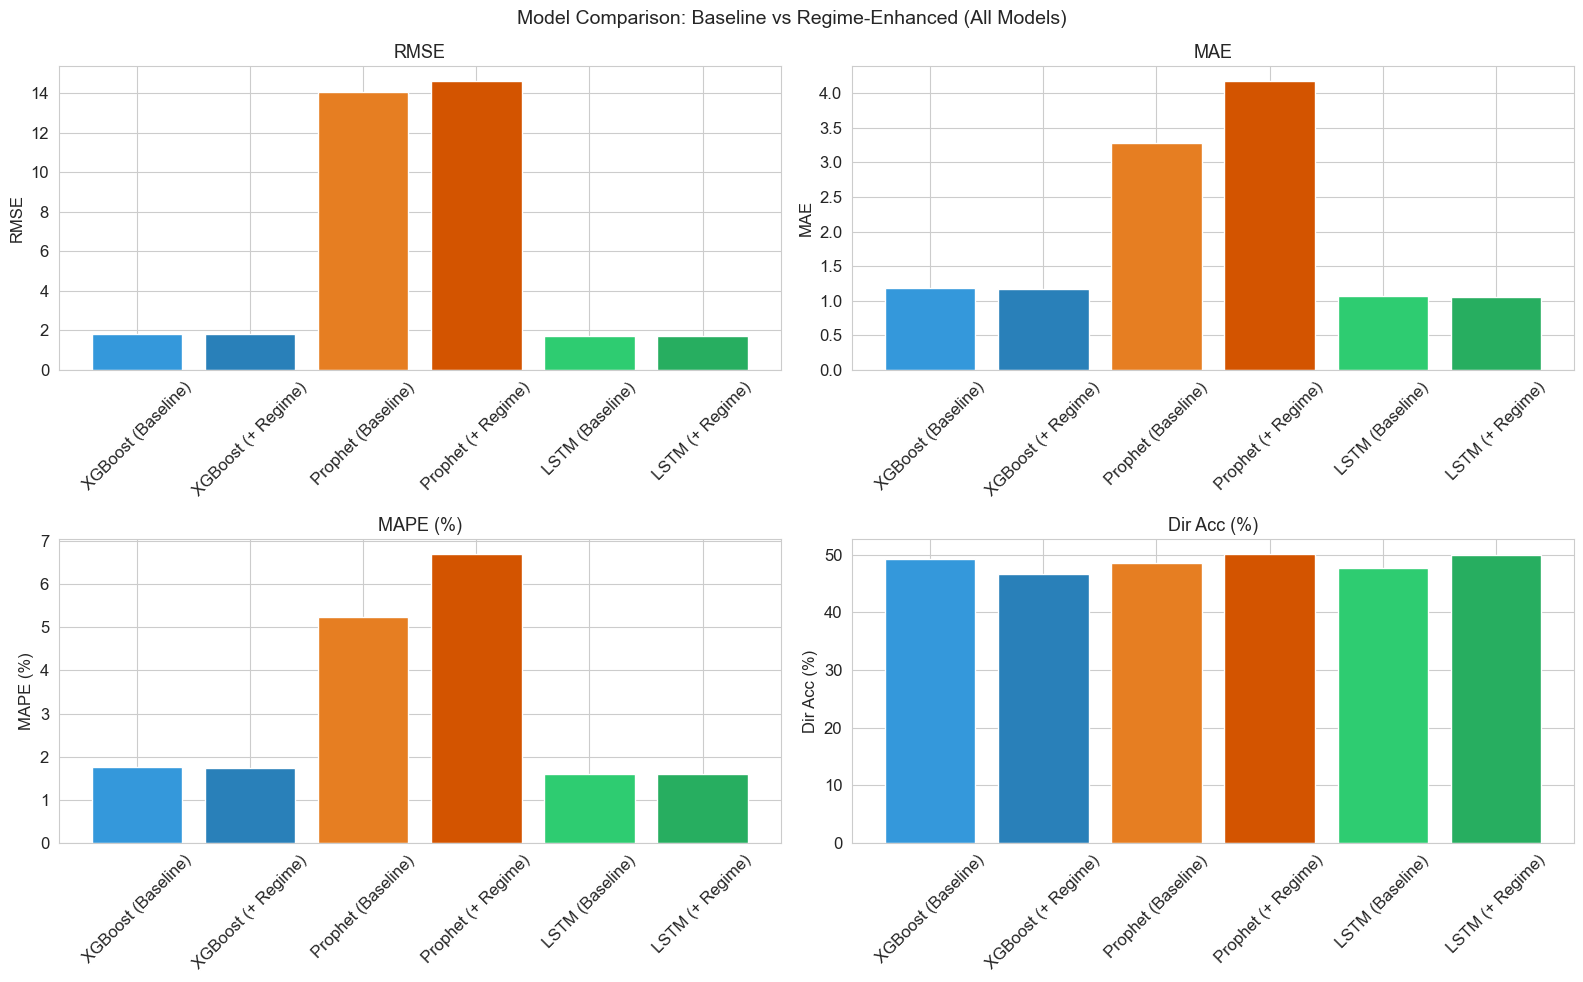

In [22]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
metrics = ['RMSE', 'MAE', 'MAPE (%)', 'Dir Acc (%)']
colors  = ['#3498db','#2980b9','#e67e22','#d35400','#2ecc71','#27ae60']

for ax, metric in zip(axes.flatten(), metrics):
    ax.bar(summary['Model'], summary[metric], color=colors)
    ax.set_title(metric, fontsize=13)
    ax.tick_params(axis='x', rotation=45)
    ax.set_ylabel(metric)

fig.suptitle('Model Comparison: Baseline vs Regime-Enhanced (All Models)', fontsize=14)
plt.tight_layout()
plt.show()

# 8. Multi-Horizon Directional Accuracy Analysis

Predict WTI price direction over **1-day, 7-day, and 30-day horizons** using the regime-enhanced XGBoost model. Longer forecast horizons tend to smooth out short-term noise, potentially yielding higher directional accuracy.

In [23]:
# Multi-horizon dataset preparation
mh = pd.read_csv('dataset_with_regime.csv', parse_dates=['observation_date'])
mh = mh.sort_values('observation_date').reset_index(drop=True)

# Add RSI and momentum features
mh['RSI_14']      = compute_rsi(mh['WTI_Price'])
mh['momentum_5']  = mh['WTI_Price'] / mh['WTI_Price'].shift(5) - 1
mh['momentum_10'] = mh['WTI_Price'] / mh['WTI_Price'].shift(10) - 1
mh['lag1']        = mh['oil_return'].shift(1)
mh['lag2']        = mh['oil_return'].shift(2)
mh['lag_price']   = mh['WTI_Price'].shift(1)

# Multi-horizon log-return targets (h trading days ahead)
for h in [1, 7, 30]:
    mh[f'target_h{h}'] = np.log(mh['WTI_Price'].shift(-h) / mh['WTI_Price'])

mh = mh.dropna().copy().reset_index(drop=True)
print(f'Multi-horizon dataset: {mh.shape[0]} rows')

# Feature list (enhanced: baseline + regime)
mh_features = [
    'Brent_Price', 'DTWEXBGS', 'EFFR', 'Gas_Price', 'Gold_Price', 'OVX_Close',
    'WCESTUS1', 'supply_shock', 'supply_shock_pct',
    'GPR', 'GPRT', 'GPRC', 'GEPUCURRENT', 'CPILFESL',
    'INDPRO', 'industrial_production_growth',
    'lag1', 'lag2', 'lag_price',
    'RSI_14', 'momentum_5', 'momentum_10',
    'rolling_entropy', 'hidden_state', 'transient_state', 'regime_label'
]

split_mh = int(len(mh) * 0.8)
mh_train = mh.iloc[:split_mh]

results_mh = []
horizon_price_preds = {}

for h in [1, 7, 30]:
    target_col_h = f'target_h{h}'
    mh_test = mh.iloc[split_mh:].dropna(subset=[target_col_h])

    model_h = xgb.XGBRegressor(**xgb_params)
    model_h.fit(mh_train[mh_features], mh_train[target_col_h])

    y_pred_h = model_h.predict(mh_test[mh_features])
    y_true_h = mh_test[target_col_h].values

    # Price predictions (for RMSE/MAE/MAPE)
    price_pred_h = mh_test['WTI_Price'].values * np.exp(y_pred_h)
    price_true_h = mh_test['WTI_Price'].values * np.exp(y_true_h)

    rmse_h = np.sqrt(mean_squared_error(price_true_h, price_pred_h))
    mae_h  = mean_absolute_error(price_true_h, price_pred_h)
    mape_h = np.mean(np.abs((price_true_h - price_pred_h) / price_true_h)) * 100
    dir_h  = np.mean(np.sign(y_pred_h) == np.sign(y_true_h)) * 100
    base_rate_h = np.mean(y_true_h > 0) * 100

    results_mh.append({
        'Horizon': f'h={h}d',
        'RMSE':        round(rmse_h, 4),
        'MAE':         round(mae_h, 4),
        'MAPE (%)':    round(mape_h, 4),
        'Dir Acc (%)': round(dir_h, 2),
        'Up-day Rate (%)': round(base_rate_h, 2),
        'n_test': len(mh_test)
    })
    horizon_price_preds[h] = (mh_test['observation_date'].values, price_true_h, price_pred_h)
    print(f'h={h}d  RMSE={rmse_h:.4f}  MAE={mae_h:.4f}  MAPE={mape_h:.4f}%  DirAcc={dir_h:.2f}%  (n={len(mh_test)})')

mh_summary = pd.DataFrame(results_mh)
display(mh_summary)

Multi-horizon dataset: 1513 rows


h=1d  RMSE=1.3447  MAE=0.9880  MAPE=1.5267%  DirAcc=46.86%  (n=303)


h=7d  RMSE=3.4561  MAE=2.4271  MAPE=3.7463%  DirAcc=63.70%  (n=303)


h=30d  RMSE=7.8638  MAE=6.6639  MAPE=10.3866%  DirAcc=45.21%  (n=303)


,Horizon,RMSE,MAE,MAPE (%),Dir Acc (%),Up-day Rate (%),n_test
0,h=1d,1.3447,0.9880,1.5267,46.86,48.51,303
1,h=7d,3.4561,2.4271,3.7463,63.70,48.51,303
2,h=30d,7.8638,6.6639,10.3866,45.21,38.94,303


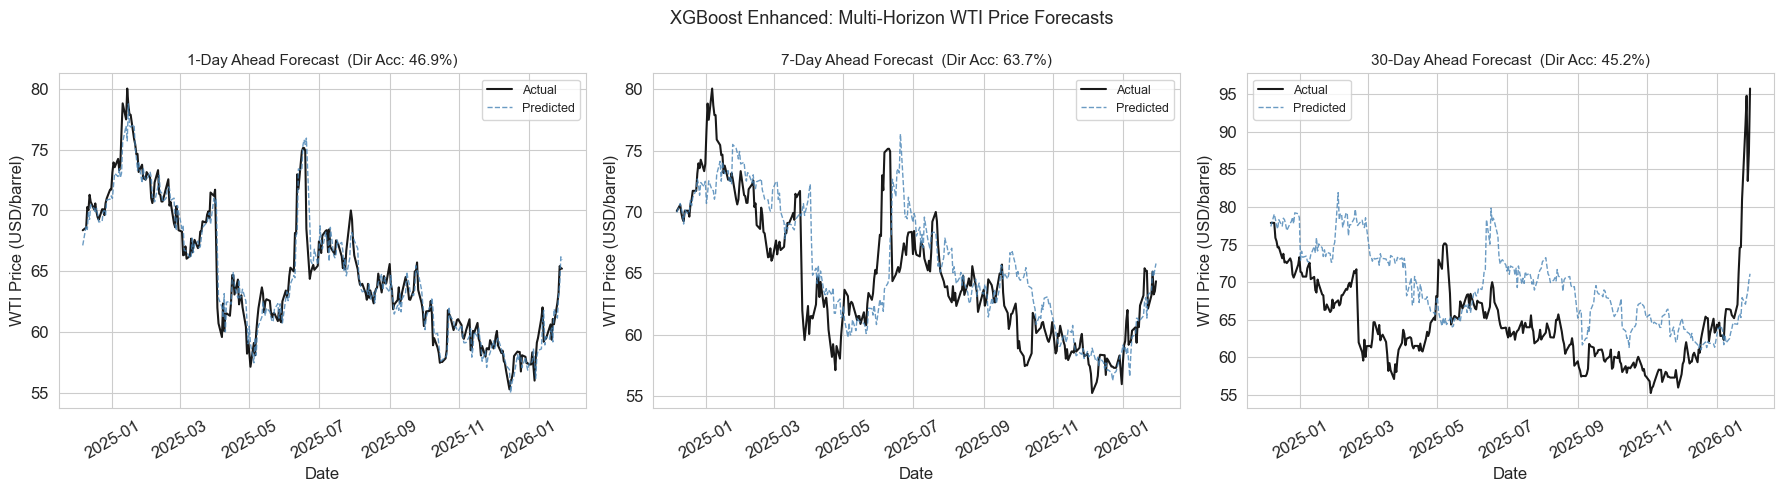

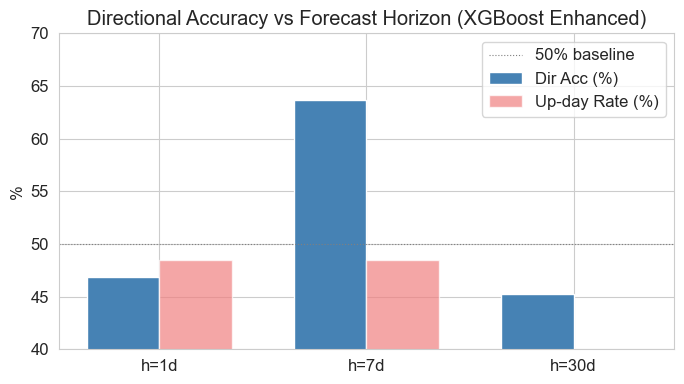

In [24]:
# Multi-horizon visualisation
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, h in zip(axes, [1, 7, 30]):
    dates, p_true, p_pred = horizon_price_preds[h]
    ax.plot(dates, p_true, color='black',     linewidth=1.5, label='Actual',    alpha=0.9)
    ax.plot(dates, p_pred, color='steelblue', linewidth=1.0, linestyle='--', label='Predicted', alpha=0.8)
    dir_acc = mh_summary.loc[mh_summary['Horizon'] == f'h={h}d', 'Dir Acc (%)'].values[0]
    ax.set_title(f'{h}-Day Ahead Forecast  (Dir Acc: {dir_acc:.1f}%)', fontsize=11)
    ax.set_xlabel('Date')
    ax.set_ylabel('WTI Price (USD/barrel)')
    ax.legend(fontsize=9)
    ax.tick_params(axis='x', rotation=30)

fig.suptitle('XGBoost Enhanced: Multi-Horizon WTI Price Forecasts', fontsize=13)
plt.tight_layout()
plt.show()

# Bar chart: Dir Acc vs Horizon
fig2, ax2 = plt.subplots(figsize=(7, 4))
horizons = mh_summary['Horizon'].tolist()
dir_accs = mh_summary['Dir Acc (%)'].tolist()
up_rates = mh_summary['Up-day Rate (%)'].tolist()
x = np.arange(len(horizons))
width = 0.35
ax2.bar(x - width/2, dir_accs, width, label='Dir Acc (%)',      color='steelblue')
ax2.bar(x + width/2, up_rates, width, label='Up-day Rate (%)', color='lightcoral', alpha=0.7)
ax2.axhline(50, color='grey', linestyle=':', linewidth=0.8, label='50% baseline')
ax2.set_xticks(x); ax2.set_xticklabels(horizons)
ax2.set_ylabel('%'); ax2.set_ylim(40, 70)
ax2.set_title('Directional Accuracy vs Forecast Horizon (XGBoost Enhanced)')
ax2.legend()
plt.tight_layout()
plt.show()